[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/02-data-science/07_seaborn.ipynb)

*Python for Data Science · Notebook 7 of 8*

# Seaborn

Statistical charts from DataFrames in one line: distributions, categories, relationships, heat maps and multi-panel grids.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Seaborn is the helpful assistant: hand over a DataFrame and say which columns matter, and it draws the statistical chart.

**What interviewers really test here:** Distribution and relationship plots, and reading them to find insight.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why Seaborn? *(Basics)*
- [ ] 2. Distributions of one variable *(Basics)*
- [ ] 3. Tidy data: the shape Seaborn wants *(Basics)*
- [ ] 4. Comparing categories *(Core)*
- [ ] 5. Relationships between numbers *(Core)*
- [ ] 6. Reading a box plot, by hand *(Core)*
- [ ] 7. Bins and smoothing can change the story *(Core)*
- [ ] 8. Figure-level functions and themes *(Advanced)*
- [ ] 9. Hidden averages and Simpson's paradox *(Advanced)*
- [ ] 10. Correlation heat maps, without fooling yourself *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### What Seaborn is

**Seaborn** is a high-level statistical visualisation library built on Matplotlib and tightly integrated with pandas (created by Michael Waskom). It maps DataFrame columns to visual properties — x, y, **hue** (colour), **size**, **style** — and performs the needed statistics (counting, averaging, density estimation, regression, confidence intervals) automatically.

### Function families

| Family | Axes-level | Figure-level |
| --- | --- | --- |
| Relational | `scatterplot`, `lineplot` | `relplot` |
| Distribution | `histplot`, `kdeplot`, `ecdfplot`, `rugplot` | `displot` |
| Categorical | `stripplot`, `swarmplot`, `boxplot`, `violinplot`, `boxenplot`, `pointplot`, `barplot`, `countplot` | `catplot` |
| Regression | `regplot`, `residplot` | `lmplot` |
| Matrix | `heatmap` | `clustermap` |
| Multi-plot | — | `pairplot`, `jointplot`, `FacetGrid`, `PairGrid` |



Axes-level functions accept `ax=` and return the Axes. Figure-level functions create their own figure and return a grid object (`FacetGrid`, `PairGrid`, `JointGrid`) whose `.figure` and `.axes` you can customise.

### Data formats and semantic mappings

Seaborn works best with **long-form (tidy)** data: one row per observation, one column per variable. Wide-form data (one column per category) is accepted by many functions but offers less control; convert with `df.melt()`.



| Parameter | Maps a column to |
| --- | --- |
| `x`, `y` | position |
| `hue` | colour |
| `size` | marker size / line width |
| `style` | marker / dash style |
| `col`, `row` (figure-level) | separate panels (facets) |

### Statistical estimation

- `barplot`/`pointplot`/`lineplot` aggregate repeated values with an **estimator** (mean by default; `estimator="median"` or `"sum"`) and show uncertainty with `errorbar=`: `("ci", 95)` bootstrap confidence interval (default), `"sd"`, `"se"`, `("pi", 50)`, or `None`.
- `kdeplot` uses a Gaussian **kernel density estimate**; `bw_adjust` changes smoothness.
- `regplot` fits ordinary least squares (`order=2` for polynomial, `logistic=True`, `lowess=True`).
- `boxplot` uses quartiles and 1.5 × IQR whiskers.

### Themes, palettes and choosing a chart

- **Themes**: `sns.set_theme(style=…)` with darkgrid, whitegrid, dark, white, ticks; `context=` paper, notebook, talk, poster.
- **Palettes**: qualitative ("deep", "muted", "pastel", "colorblind") for categories; sequential ("rocket", "viridis", "Blues") for ordered values; diverging ("coolwarm", "vlag") for values around a centre such as correlation.



| Question | Seaborn chart |
| --- | --- |
| How is one variable distributed? | histplot, kdeplot, ecdfplot, boxplot |
| How do groups compare? | barplot, boxplot, violinplot, stripplot |
| How do two numbers relate? | scatterplot, regplot, jointplot |
| How does a value change over time? | lineplot |
| Which variables are correlated? | heatmap of corr, pairplot |

---
# Part 2: Lessons, step by step

## Lesson 1: Why Seaborn?

*Level: Basics*

**Seaborn** is built on Matplotlib and designed for **statistical** charts from **DataFrames**. You name the columns, and Seaborn groups, counts, averages, colours and labels for you:



```python
import seaborn as sns
sns.barplot(data=df, x="day", y="bill")      # mean bill per day, with error bars
sns.scatterplot(data=df, x="bill", y="tip", hue="sex")
```



The same charts in plain Matplotlib need loops to split groups, compute statistics and build legends — exactly what the "brute force" answers in this topic do. Seaborn functions return a Matplotlib Axes, so you can still customise with `ax.set_title(...)`.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

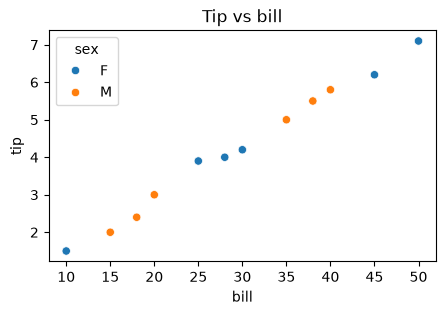

In [2]:
TIPS = pd.DataFrame({
    "bill": [10, 20, 30, 40, 50, 15, 25, 35, 45, 18, 28, 38],
    "tip": [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0, 6.2, 2.4, 4.0, 5.5],
    "day": ["Sat", "Sun", "Sat", "Sun", "Sat", "Fri", "Fri", "Sun", "Sat", "Fri", "Sun", "Sat"],
    "sex": ["F", "M", "F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
})


def why_seaborn():
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.scatterplot(data=TIPS, x="bill", y="tip", hue="sex", ax=ax)
    ax.set_title("Tip vs bill")


why_seaborn()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 2: Distributions of one variable

*Level: Basics*

| Function | Shows |
| --- | --- |
| `sns.histplot(data=df, x="bill", bins=10)` | counts in bins (add `kde=True` for a curve) |
| `sns.kdeplot(data=df, x="bill")` | smooth density estimate |
| `sns.ecdfplot(data=df, x="bill")` | share of values ≤ x (no binning choices) |
| `hue="sex"`, `multiple="stack" \| "dodge" \| "fill"` | compare groups |



Look for: centre, spread, skew (a long tail on one side), several peaks, and outliers.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

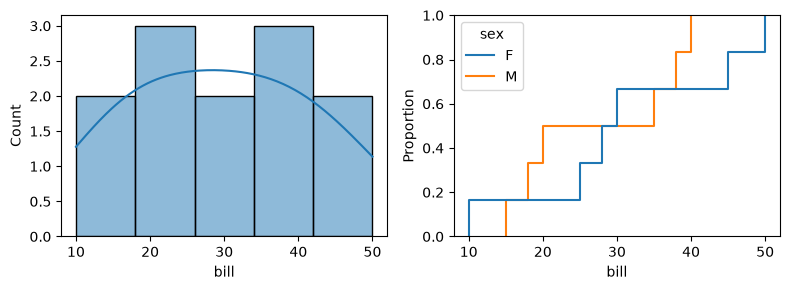

In [3]:
TIPS = pd.DataFrame({
    "bill": [10, 20, 30, 40, 50, 15, 25, 35, 45, 18, 28, 38],
    "tip": [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0, 6.2, 2.4, 4.0, 5.5],
    "day": ["Sat", "Sun", "Sat", "Sun", "Sat", "Fri", "Fri", "Sun", "Sat", "Fri", "Sun", "Sat"],
    "sex": ["F", "M", "F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
})


def distributions_demo():
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
    sns.histplot(data=TIPS, x="bill", bins=5, kde=True, ax=left)
    sns.ecdfplot(data=TIPS, x="bill", hue="sex", ax=right)
    fig.tight_layout()


distributions_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9), [Q15](#q15), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 3: Tidy data: the shape Seaborn wants

*Level: Basics*

Seaborn works from **long** data: one row per observation, one column per variable. Then each visual choice simply names a column.



| Wide (hard to plot) | Long (tidy) |
| --- | --- |
| columns: name, math, english | columns: name, subject, score |



```python
tidy = wide.melt(id_vars="name", var_name="subject", value_name="score")
sns.barplot(data=tidy, x="name", y="score", hue="subject")
```



**Test:** if a column name contains a value (2023, 2024, math, english), it's wide. Melt it.



Once it's tidy, moving a column from `hue` to `x`, or to `col` for separate panels, changes the question you're asking without any other work.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

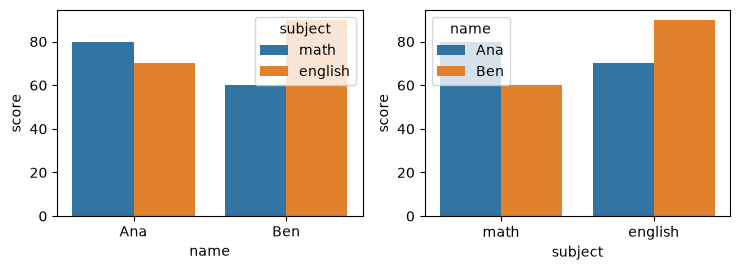

In [4]:
def tidy_demo():
    wide = pd.DataFrame({"name": ["Ana", "Ben"], "math": [80, 60], "english": [70, 90]})
    tidy = wide.melt(id_vars="name", var_name="subject", value_name="score")
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    sns.barplot(data=tidy, x="name", y="score", hue="subject", ax=left)
    sns.barplot(data=tidy, x="subject", y="score", hue="name", ax=right)
    fig.tight_layout()


tidy_demo()

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 4: Comparing categories

*Level: Core*

| Function | Shows per category |
| --- | --- |
| `countplot` | number of rows |
| `barplot` | mean (or `estimator="sum"`) with a confidence interval (`errorbar=None` to hide) |
| `pointplot` | mean as points joined by lines |
| `boxplot` | median, quartiles, whiskers, outliers |
| `violinplot` | box plot + density shape |
| `stripplot` / `swarmplot` | every individual value |



Control category order with `order=[...]`, add a second grouping with `hue=`, and flip to horizontal by swapping x and y.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

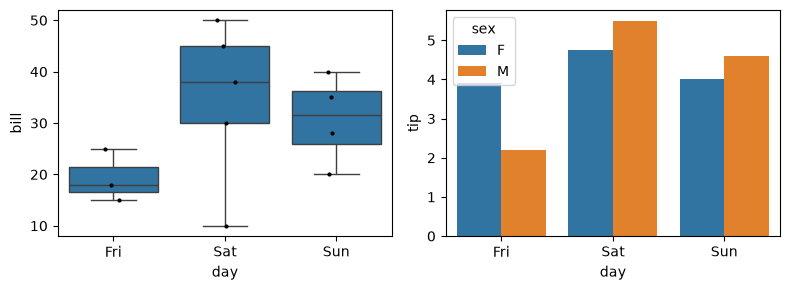

In [5]:
TIPS = pd.DataFrame({
    "bill": [10, 20, 30, 40, 50, 15, 25, 35, 45, 18, 28, 38],
    "tip": [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0, 6.2, 2.4, 4.0, 5.5],
    "day": ["Sat", "Sun", "Sat", "Sun", "Sat", "Fri", "Fri", "Sun", "Sat", "Fri", "Sun", "Sat"],
    "sex": ["F", "M", "F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
})


def categories_demo():
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
    order = ["Fri", "Sat", "Sun"]
    sns.boxplot(data=TIPS, x="day", y="bill", order=order, ax=left)
    sns.stripplot(data=TIPS, x="day", y="bill", order=order, color="black", size=3, ax=left)
    sns.barplot(data=TIPS, x="day", y="tip", hue="sex", order=order, errorbar=None, ax=right)
    fig.tight_layout()


categories_demo()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q2](#q2), [Q3](#q3), [Q7](#q7), [Q13](#q13), [Q8](#q8), [Q19](#q19), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 5: Relationships between numbers

*Level: Core*

```python
sns.scatterplot(data=df, x="bill", y="tip", hue="day", size="party")
sns.lineplot(data=df, x="month", y="sales", hue="region")   # averages repeated x values + band
sns.regplot(data=df, x="bill", y="tip")                     # scatter + fitted line
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
```



A correlation heat map is the quickest overview of which numeric columns move together (+1), oppositely (−1) or not at all (0).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

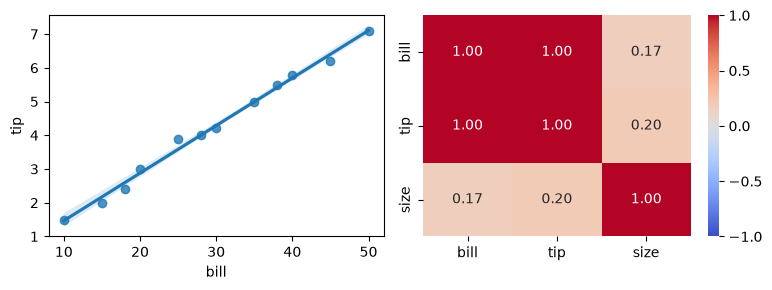

In [6]:
TIPS = pd.DataFrame({
    "bill": [10, 20, 30, 40, 50, 15, 25, 35, 45, 18, 28, 38],
    "tip": [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0, 6.2, 2.4, 4.0, 5.5],
    "day": ["Sat", "Sun", "Sat", "Sun", "Sat", "Fri", "Fri", "Sun", "Sat", "Fri", "Sun", "Sat"],
    "sex": ["F", "M", "F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
})


def relationships_demo():
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
    sns.regplot(data=TIPS, x="bill", y="tip", ax=left, seed=0, n_boot=200)
    corr = TIPS[["bill", "tip"]].assign(size=np.arange(len(TIPS)) % 4 + 1).corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=right)
    fig.tight_layout()


relationships_demo()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q12](#q12), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 6: Reading a box plot, by hand

*Level: Core*

Values: 2, 4, 4, 5, 6, 7, 9, 15.



| Part of the box plot | Calculation | Value |
| --- | --- | --- |
| Bottom of box (Q1) | 25th percentile | 4 |
| Line in box (median) | between 5 and 6 | 5.5 |
| Top of box (Q3) | 75th percentile | 7.5 |
| Box height (IQR) | 7.5 − 4 | 3.5 |
| Upper fence | 7.5 + 1.5 × 3.5 | 12.75 |
| Lower fence | 4 − 1.5 × 3.5 | −1.25 |
| Upper whisker | largest value within the fence | 9 |
| Lower whisker | smallest value within the fence | 2 |
| Dot | beyond the fence | 15 |



#### How to read one



- The box holds the middle 50% of the data.
- Median near the bottom of the box, with a long upper whisker, means right-skewed data.
- Comparing groups? Do the boxes overlap, or are they clearly apart?



**Limitation:** a box plot hides shape. Two peaks look just like one. Add a strip plot, or use a violin plot, when in doubt.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

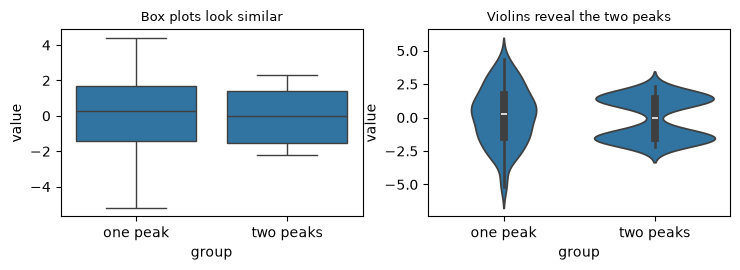

In [7]:
def hidden_shape():
    r = np.random.default_rng(0)
    one_peak = r.normal(0, 2.2, 150)
    two_peaks = np.r_[r.normal(-1.5, 0.3, 75), r.normal(1.5, 0.3, 75)]
    df = pd.DataFrame({"group": ["one peak"] * 150 + ["two peaks"] * 150, "value": np.r_[one_peak, two_peaks]})
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    sns.boxplot(data=df, x="group", y="value", ax=left)
    left.set_title("Box plots look similar", fontsize=9)
    sns.violinplot(data=df, x="group", y="value", ax=right)
    right.set_title("Violins reveal the two peaks", fontsize=9)
    fig.tight_layout()


hidden_shape()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 7: Bins and smoothing can change the story

*Level: Core*

Histograms and density curves involve a choice, and that choice can hide or invent features.



- **Too few bins:** a two-peaked distribution can look flat, or like one lump.
- **Too many bins:** random noise looks like real structure.
- **KDE smoothing:** `bw_adjust` does the same job. A KDE can also show values that can't exist, such as negative ages.



**Good habit:** try several bin counts before concluding anything. If your finding disappears when the bins change, it wasn't solid.



To compare groups with different sizes, use `stat="density"` and `common_norm=False`, so a larger group doesn't appear more important. The **ECDF** avoids bins entirely: it shows the share of values at or below each point.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

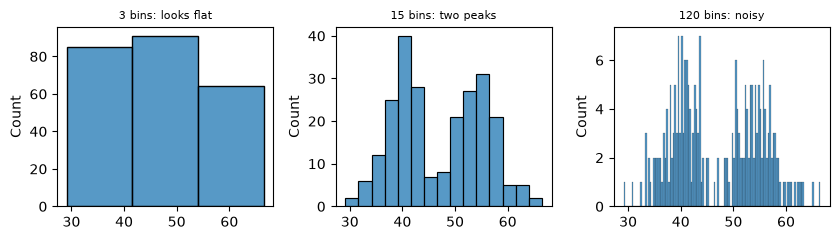

In [8]:
def bins_change_story():
    r = np.random.default_rng(1)
    values = np.r_[r.normal(40, 4, 120), r.normal(55, 4, 120)]
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.5), sharex=True)
    for ax, bins, name in zip(axes, [3, 15, 120], ["3 bins: looks flat", "15 bins: two peaks", "120 bins: noisy"]):
        sns.histplot(values, bins=bins, ax=ax)
        ax.set_title(name, fontsize=8)
    fig.tight_layout()


bins_change_story()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 8: Figure-level functions and themes

*Level: Advanced*

**Axes-level** functions (`scatterplot`, `boxplot` …) draw on one Axes you pass with `ax=`. **Figure-level** functions build a whole grid and return a grid object:



| Figure-level | Wraps | Grid by |
| --- | --- | --- |
| `relplot` | scatterplot / lineplot | `col=`, `row=` |
| `displot` | histplot / kdeplot / ecdfplot | `col=`, `row=` |
| `catplot` | box / violin / bar / strip … | `col=`, `row=` |
| `pairplot` | every pair of columns | automatic |
| `jointplot` | scatter + marginal distributions | automatic |



Set the look once with `sns.set_theme(style="whitegrid", palette="deep", font_scale=1.1)`. Palettes: `"deep"`, `"pastel"`, `"viridis"`, `"coolwarm"` (diverging).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

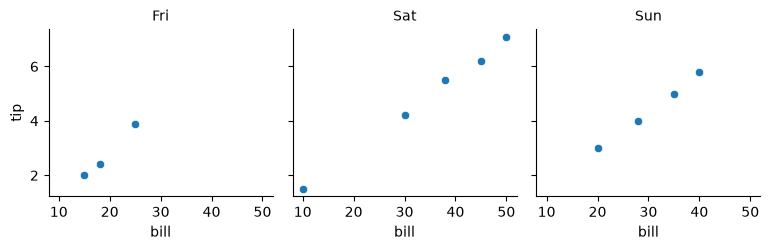

In [9]:
TIPS = pd.DataFrame({
    "bill": [10, 20, 30, 40, 50, 15, 25, 35, 45, 18, 28, 38],
    "tip": [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0, 6.2, 2.4, 4.0, 5.5],
    "day": ["Sat", "Sun", "Sat", "Sun", "Sat", "Fri", "Fri", "Sun", "Sat", "Fri", "Sun", "Sat"],
    "sex": ["F", "M", "F", "M", "F", "M", "F", "M", "F", "M", "F", "M"],
})


def figure_level_demo():
    g = sns.relplot(data=TIPS, x="bill", y="tip", col="day", col_order=["Fri", "Sat", "Sun"], height=2.6, aspect=1)
    g.set_titles("{col_name}")


figure_level_demo()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: Hidden averages and Simpson's paradox

*Level: Advanced*

`sns.barplot` quietly **computes an average** and draws an error bar. Very different data can yield identical bars, so look at the raw points too.



#### Simpson's paradox: a real shock



Recovery rates for two treatments, from a well-known kidney-stone study:



| Stone size | Treatment A | Treatment B | Better |
| --- | --- | --- | --- |
| Small | 81 / 87 = **93%** | 234 / 270 = 87% | A |
| Large | 192 / 263 = **73%** | 55 / 80 = 69% | A |
| **All patients** | 273 / 350 = 78% | 289 / 350 = **83%** | **B?!** |



A wins in **both** groups but loses overall. The reason: doctors gave A mostly to the hard, large-stone cases. Stone size affects both the choice of treatment and the outcome.



**Lesson:** before trusting an overall comparison, split by likely confounders, which is what `hue` and `col` make easy. Which view is right depends on how the data arose, so think about the cause, not just the numbers.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

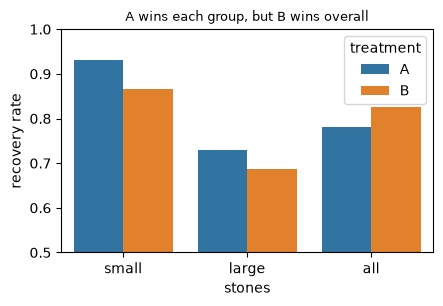

In [10]:
def simpson_chart():
    df = pd.DataFrame({"stones": ["small", "small", "large", "large", "all", "all"], "treatment": ["A", "B", "A", "B", "A", "B"], "recovered": [81, 234, 192, 55, 273, 289], "patients": [87, 270, 263, 80, 350, 350]})
    df["rate"] = df["recovered"] / df["patients"]
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    sns.barplot(data=df, x="stones", y="rate", hue="treatment", ax=ax)
    ax.set_ylim(0.5, 1)
    ax.set_ylabel("recovery rate")
    ax.set_title("A wins each group, but B wins overall", fontsize=9)


simpson_chart()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q13](#q13), [Q8](#q8), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 10: Correlation heat maps, without fooling yourself

*Level: Advanced*

A heat map of `df.corr(numeric_only=True)` gives a fast overview. Use it well:



- Use a **diverging** palette with `vmin=-1, vmax=1, center=0`, so colour means the same in every chart.
- Add numbers with `annot=True, fmt=".2f"`, and hide the repeated half with a `mask`.



#### What it can't tell you



- Only straight-line relationships count: a perfect U shape can have r = 0.
- One outlier can create or destroy a correlation.
- With 20 columns you're looking at 190 pairs, so a few will look strong by chance.
- Correlation isn't cause.



So check interesting cells with a scatter plot, or a `pairplot` of a few columns.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

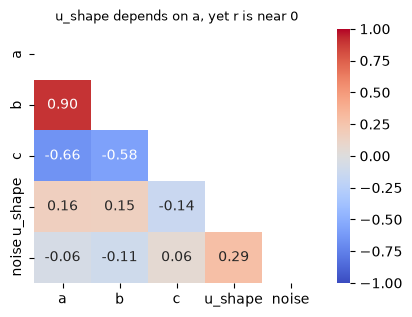

In [11]:
def masked_heatmap():
    r = np.random.default_rng(0)
    a = r.normal(size=100)
    df = pd.DataFrame({"a": a, "b": a * 2 + r.normal(size=100), "c": -a + r.normal(size=100), "u_shape": a ** 2, "noise": r.normal(size=100)})
    corr = df.corr()
    hide_upper = np.triu(np.ones_like(corr, dtype=bool))
    fig, ax = plt.subplots(figsize=(4.6, 3.3))
    sns.heatmap(corr, mask=hide_upper, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
    ax.set_title("u_shape depends on a, yet r is near 0", fontsize=9)


masked_heatmap()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [12]:
def rects(ax):
    from matplotlib.patches import Rectangle
    return [p for p in ax.patches if isinstance(p, Rectangle) and p.get_height() > 0]

SCORES = {"group": ["A", "A", "A", "A", "B", "B", "B", "B", "C", "C", "C", "C"],
          "value": [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}

def ticks(ax, axis="x"):
    labels = ax.get_xticklabels() if axis == "x" else ax.get_yticklabels()
    return [t.get_text() for t in labels]

BILLS = {"bill": [10, 20, 30, 40, 50, 15, 25, 35], "tip": [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0],
         "sex": ["F", "M", "F", "M", "F", "M", "F", "M"]}


<a id="q1"></a>
### Q1. Histogram

🟢 Warm-up · *histplot*

Draw a histogram of `values` with `bins` bins.

**Examples**

- `values = [1, 2, 2, 3, 3, 3, 4, 4, 5, 5], bins = 4` → `'4 bars whose heights add up to 10'`

In [ ]:
def histogram(values, bins):
    """
    Draw a histogram of values with bins bins.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(histogram, [(([1, 2, 2, 3, 3, 3, 4, 4, 5, 5], 4), "4 bars whose heights add up to 10")], verify=lambda a, ax: len(rects(ax)) <= a[1] and round(sum(p.get_height() for p in rects(ax))) == len(a[0]))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count values per bin with NumPy and draw bars with Matplotlib.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.histplot(x=values, bins=bins)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count values per bin with NumPy and draw bars with Matplotlib.

```python
def histogram(values, bins):
    counts, edges = np.histogram(values, bins=bins)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", edgecolor="white")
    ax.set_ylabel("Count")
    return ax
```

**Cost:** O(n) time, O(bins) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.histplot(x=values, bins=bins)`.

```python
def histogram(values, bins):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.histplot(x=values, bins=bins, ax=ax)
    return ax
```

**Cost:** O(n) time, O(bins) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count values per bin with NumPy and draw bars with Matplotlib. That costs O(n) time and O(bins) space."

"I can do better: `sns.histplot(x=values, bins=bins)`. That's O(n) time and O(bins) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/histogram)

<a id="q2"></a>
### Q2. Box Plot by Group

🟢 Warm-up · *boxplot*

Draw one box of `value` per `group`.

**Examples**

- `data = {'group': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C'], 'value': [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}` → `'3 boxes labelled A, B, C'`

In [ ]:
def box_by_group(data):
    """
    Draw one box of value per group.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(box_by_group, [((SCORES,), "3 boxes labelled A, B, C")], verify=lambda a, ax: ticks(ax) == ["A", "B", "C"])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split the values per group yourself and call Matplotlib's boxplot.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.boxplot(data=df, x='group', y='value')` — works directly on the DataFrame columns.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Split the values per group yourself and call Matplotlib's boxplot.

```python
def box_by_group(data):
    groups = {}
    for g, v in zip(data["group"], data["value"]):
        groups.setdefault(g, []).append(v)
    names = sorted(groups)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.boxplot([groups[n] for n in names])
    ax.set_xticks(range(1, len(names) + 1), names)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.boxplot(data=df, x='group', y='value')` — works directly on the DataFrame columns.

```python
def box_by_group(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.boxplot(data=pd.DataFrame(data), x="group", y="value", ax=ax)
    return ax
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split the values per group yourself and call Matplotlib's boxplot. That costs O(n) time and O(n) space."

"I can do better: `sns.boxplot(data=df, x='group', y='value')` — works directly on the DataFrame columns. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/box-plot-by-group)

<a id="q3"></a>
### Q3. Violin Plot

🟢 Warm-up · *violinplot*

Draw a violin (box plot + density shape) of value per group.

**Examples**

- `data = {'group': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C'], 'value': [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}` → `'3 violins labelled A, B, C'`

In [ ]:
def violins(data):
    """
    Draw a violin (box plot + density shape) of value per group.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(violins, [((SCORES,), "3 violins labelled A, B, C")], verify=lambda a, ax: ticks(ax) == ["A", "B", "C"])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Group values by hand and use Matplotlib's violinplot.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.violinplot(data=df, x='group', y='value')`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Group values by hand and use Matplotlib's violinplot.

```python
def violins(data):
    groups = {}
    for g, v in zip(data["group"], data["value"]):
        groups.setdefault(g, []).append(v)
    names = sorted(groups)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.violinplot([groups[n] for n in names], showmedians=True)
    ax.set_xticks(range(1, len(names) + 1), names)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.violinplot(data=df, x='group', y='value')`.

```python
def violins(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.violinplot(data=pd.DataFrame(data), x="group", y="value", ax=ax)
    return ax
```

**Cost:** O(n · grid) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Group values by hand and use Matplotlib's violinplot. That costs O(n) time and O(n) space."

"I can do better: `sns.violinplot(data=df, x='group', y='value')`. That's O(n · grid) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/violin-plot)

<a id="q4"></a>
### Q4. Count Plot

🟢 Warm-up · *countplot*

Draw one bar per category showing how many times it appears.

**Examples**

- `items = ['tea', 'coffee', 'tea', 'juice', 'tea', 'coffee']` → `'bars of height 3, 2, 1'`

In [ ]:
def count_plot(items):
    """
    Draw one bar per category showing how many times it appears.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(count_plot, [((["tea", "coffee", "tea", "juice", "tea", "coffee"],), "bars of height 3, 2, 1")], verify=lambda a, ax: sorted(round(p.get_height()) for p in rects(ax)) == [1, 2, 3])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a dict, then draw bars.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.countplot(x=items)` counts and draws.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count in a dict, then draw bars.

```python
def count_plot(items):
    counts = {}
    for it in items:
        counts[it] = counts.get(it, 0) + 1
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(list(counts), list(counts.values()))
    ax.set_ylabel("count")
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.countplot(x=items)` counts and draws.

```python
def count_plot(items):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.countplot(x=items, ax=ax)
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a dict, then draw bars. That costs O(n) time and O(k) space."

"I can do better: `sns.countplot(x=items)` counts and draws. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/count-plot)

<a id="q5"></a>
### Q5. Bar Plot of Averages

🟢 Warm-up · *barplot*

Draw the mean value per group as bars (no error bars).

**Examples**

- `data = {'group': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C'], 'value': [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}` → `'bars at the group means 4.5, 7.5, 2.75'`

In [ ]:
def mean_bars(data):
    """
    Draw the mean value per group as bars (no error bars).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mean_bars, [((SCORES,), "bars at the group means 4.5, 7.5, 2.75")], verify=lambda a, ax: sorted(round(p.get_height(), 2) for p in rects(ax)) == [2.75, 4.5, 7.5])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each group's mean in a loop and draw bars.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.barplot(data=df, x='group', y='value', errorbar=None)` aggregates (mean by default).

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute each group's mean in a loop and draw bars.

```python
def mean_bars(data):
    sums, counts = {}, {}
    for g, v in zip(data["group"], data["value"]):
        sums[g] = sums.get(g, 0) + v
        counts[g] = counts.get(g, 0) + 1
    names = sorted(sums)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(names, [sums[n] / counts[n] for n in names])
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.barplot(data=df, x='group', y='value', errorbar=None)` aggregates (mean by default).

```python
def mean_bars(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.barplot(data=pd.DataFrame(data), x="group", y="value", errorbar=None, ax=ax)
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each group's mean in a loop and draw bars. That costs O(n) time and O(k) space."

"I can do better: `sns.barplot(data=df, x='group', y='value', errorbar=None)` aggregates (mean by default). That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/bar-plot-of-averages)

<a id="q6"></a>
### Q6. Scatter Coloured by Group

🟢 Warm-up · *scatterplot(hue=)*

Scatter bill vs tip, coloured by sex, with a legend.

**Examples**

- `data = {'bill': [10, 20, 30, 40, 50, 15, 25, 35], 'tip': [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0], 'sex': ['F', 'M', 'F', 'M', 'F', 'M', 'F', 'M']}` → `'8 points in 2 colours with a 2-entry legend'`

In [ ]:
def scatter_hue(data):
    """
    Scatter bill vs tip, coloured by sex, with a legend.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scatter_hue, [((BILLS,), "8 points in 2 colours with a 2-entry legend")], verify=lambda a, ax: sum(len(c.get_offsets()) for c in ax.collections) == 8 and ax.get_legend() is not None and len(ax.get_legend().get_texts()) >= 2)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over groups, scatter each with its own label, then add a legend.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.scatterplot(data=df, x='bill', y='tip', hue='sex')` — colours and legend automatically.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop over groups, scatter each with its own label, then add a legend.

```python
def scatter_hue(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    for sex in sorted(set(data["sex"])):
        xs = [b for b, s in zip(data["bill"], data["sex"]) if s == sex]
        ys = [t for t, s in zip(data["tip"], data["sex"]) if s == sex]
        ax.scatter(xs, ys, label=sex)
    ax.set(xlabel="bill", ylabel="tip")
    ax.legend(title="sex")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.scatterplot(data=df, x='bill', y='tip', hue='sex')` — colours and legend automatically.

```python
def scatter_hue(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.scatterplot(data=pd.DataFrame(data), x="bill", y="tip", hue="sex", ax=ax)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over groups, scatter each with its own label, then add a legend. That costs O(n) time and O(n) space."

"I can do better: `sns.scatterplot(data=df, x='bill', y='tip', hue='sex')` — colours and legend automatically. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/scatter-coloured-by-group)

<a id="q7"></a>
### Q7. Strip Plot

🟢 Warm-up · *stripplot*

Show every individual value per group as a jittered dot.

**Examples**

- `data = {'group': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C'], 'value': [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}` → `'12 dots in 3 columns'`

In [ ]:
def strip(data):
    """
    Show every individual value per group as a jittered dot.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(strip, [((SCORES,), "12 dots in 3 columns")], verify=lambda a, ax: sum(len(c.get_offsets()) for c in ax.collections) == 12)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add a small random horizontal jitter to each group's x position and scatter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.stripplot(data=df, x='group', y='value', jitter=True)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Add a small random horizontal jitter to each group's x position and scatter.

```python
def strip(data):
    rng = np.random.default_rng(0)
    names = sorted(set(data["group"]))
    fig, ax = plt.subplots(figsize=(5, 3))
    for i, n in enumerate(names):
        ys = [v for g, v in zip(data["group"], data["value"]) if g == n]
        ax.scatter(i + rng.uniform(-0.1, 0.1, len(ys)), ys)
    ax.set_xticks(range(len(names)), names)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.stripplot(data=df, x='group', y='value', jitter=True)`.

```python
def strip(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.stripplot(data=pd.DataFrame(data), x="group", y="value", jitter=0.1, ax=ax)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add a small random horizontal jitter to each group's x position and scatter. That costs O(n) time and O(n) space."

"I can do better: `sns.stripplot(data=df, x='group', y='value', jitter=True)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/strip-plot)

<a id="q8"></a>
### Q8. Bars in a Chosen Order

🟢 Warm-up · *order=*

Draw a count plot whose bars follow the given category order.

**Examples**

- `items = ['low', 'high', 'mid', 'low', 'mid', 'low'], order = ['low', 'mid', 'high']` → `'bars labelled low, mid, high in that order'`

In [ ]:
def ordered_counts(items, order):
    """
    Draw a count plot whose bars follow the given category order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ordered_counts, [((["low", "high", "mid", "low", "mid", "low"], ["low", "mid", "high"]), "bars labelled low, mid, high in that order")], verify=lambda a, ax: ticks(ax) == a[1])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count, then draw the bars in the requested order by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.countplot(x=items, order=order)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count, then draw the bars in the requested order by hand.

```python
def ordered_counts(items, order):
    counts = {k: 0 for k in order}
    for it in items:
        counts[it] += 1
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(order, [counts[k] for k in order])
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.countplot(x=items, order=order)`.

```python
def ordered_counts(items, order):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.countplot(x=items, order=order, ax=ax)
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count, then draw the bars in the requested order by hand. That costs O(n) time and O(k) space."

"I can do better: `sns.countplot(x=items, order=order)`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/bars-in-a-chosen-order)

<a id="q9"></a>
### Q9. Smooth Density Curve

🟡 Interview standard · *kdeplot*

Draw a smooth density (KDE) curve of the values.

**Examples**

- `values = [2, 3, 3, 4, 4, 4, 5, 5, 6, 8]` → `'one smooth curve'`

In [ ]:
def density(values):
    """
    Draw a smooth density (KDE) curve of the values.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(density, [(([2, 3, 3, 4, 4, 4, 5, 5, 6, 8],), "one smooth curve")], verify=lambda a, ax: len(ax.lines) >= 1)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up a Gaussian bump around every value on a grid of x positions (kernel density estimation by hand).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.kdeplot(x=values)` picks the bandwidth for you.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Add up a Gaussian bump around every value on a grid of x positions (kernel density estimation by hand).

```python
def density(values):
    v = np.array(values, dtype=float)
    bw = 1.06 * v.std() * len(v) ** (-1 / 5)
    grid = np.linspace(v.min() - 3 * bw, v.max() + 3 * bw, 200)
    dens = np.exp(-0.5 * ((grid[:, None] - v[None, :]) / bw) ** 2).sum(axis=1)
    dens /= len(v) * bw * np.sqrt(2 * np.pi)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(grid, dens)
    ax.set_ylabel("Density")
    return ax
```

**Cost:** O(n · grid) time, O(grid) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.kdeplot(x=values)` picks the bandwidth for you.

```python
def density(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.kdeplot(x=values, ax=ax)
    return ax
```

**Cost:** O(n · grid) time, O(grid) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up a Gaussian bump around every value on a grid of x positions (kernel density estimation by hand). That costs O(n · grid) time and O(grid) space."

"I can do better: `sns.kdeplot(x=values)` picks the bandwidth for you. That's O(n · grid) time and O(grid) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/smooth-density-curve)

<a id="q10"></a>
### Q10. Lines per Group Over Time

🟡 Interview standard · *lineplot(hue=)*

Draw one line per region of sales over months.

**Examples**

- `data = {'month': [1, 2, 3, 1, 2, 3], 'sales': [5, 7, 6, 3, 4, 8], 'region': ['N', 'N', 'N', 'S', 'S', 'S']}` → `'2 lines with a legend'`

In [ ]:
def lines_by_region(data):
    """
    Draw one line per region of sales over months.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lines_by_region, [(({"month": [1, 2, 3, 1, 2, 3], "sales": [5, 7, 6, 3, 4, 8], "region": ["N", "N", "N", "S", "S", "S"]},), "2 lines with a legend")], verify=lambda a, ax: len([l for l in ax.lines if len(l.get_xdata()) == 3]) == 2)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Filter each region and plot it separately.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.lineplot(data=df, x='month', y='sales', hue='region')`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Filter each region and plot it separately.

```python
def lines_by_region(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    for region in sorted(set(data["region"])):
        months = [m for m, r in zip(data["month"], data["region"]) if r == region]
        sales = [s for s, r in zip(data["sales"], data["region"]) if r == region]
        ax.plot(months, sales, label=region)
    ax.legend(title="region")
    return ax
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.lineplot(data=df, x='month', y='sales', hue='region')`.

```python
def lines_by_region(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.lineplot(data=pd.DataFrame(data), x="month", y="sales", hue="region", ax=ax)
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Filter each region and plot it separately. That costs O(n·k) time and O(n) space."

"I can do better: `sns.lineplot(data=df, x='month', y='sales', hue='region')`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/lines-per-group-over-time)

<a id="q11"></a>
### Q11. Correlation Heat Map

🟡 Interview standard · *heatmap(annot=True)*

Draw the correlation matrix of the numeric columns as a heat map with the numbers written in each cell.

**Examples**

- `data = {'a': [1, 2, 3, 4], 'b': [2, 4, 5, 8], 'c': [4, 3, 2, 1]}` → `'3 × 3 coloured grid with 9 numbers'`

In [ ]:
def corr_heatmap(data):
    """
    Draw the correlation matrix of the numeric columns as a heat map with the
    numbers written in each cell.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(corr_heatmap, [(({"a": [1, 2, 3, 4], "b": [2, 4, 5, 8], "c": [4, 3, 2, 1]},), "3 × 3 coloured grid with 9 numbers")], verify=lambda a, ax: len([t for t in ax.texts if t.get_text().strip()]) == 9)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

imshow the matrix and loop over cells writing each number with ax.text.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.heatmap(df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** imshow the matrix and loop over cells writing each number with ax.text.

```python
def corr_heatmap(data):
    df = pd.DataFrame(data)
    corr = df.corr().values
    fig, ax = plt.subplots(figsize=(4, 3.2))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center")
    ax.set_xticks(range(len(df.columns)), df.columns)
    ax.set_yticks(range(len(df.columns)), df.columns)
    fig.colorbar(im)
    return ax
```

**Cost:** O(k²) time, O(k²) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.heatmap(df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)`.

```python
def corr_heatmap(data):
    fig, ax = plt.subplots(figsize=(4, 3.2))
    sns.heatmap(pd.DataFrame(data).corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    return ax
```

**Cost:** O(n·k²) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: imshow the matrix and loop over cells writing each number with ax.text. That costs O(k²) time and O(k²) space."

"I can do better: `sns.heatmap(df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)`. That's O(n·k²) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/correlation-heat-map)

<a id="q12"></a>
### Q12. Scatter With a Trend Line

🟡 Interview standard · *regplot*

Scatter bill vs tip and add the best-fit straight line.

**Examples**

- `data = {'bill': [10, 20, 30, 40, 50, 15, 25, 35], 'tip': [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0], 'sex': ['F', 'M', 'F', 'M', 'F', 'M', 'F', 'M']}` → `'8 points and a fitted line'`

In [ ]:
def trend_line(data):
    """
    Scatter bill vs tip and add the best-fit straight line.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(trend_line, [((BILLS,), "8 points and a fitted line")], verify=lambda a, ax: len(ax.lines) >= 1 and sum(len(c.get_offsets()) for c in ax.collections if c.get_offsets().shape[0] == 8) == 8)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fit the line with `np.polyfit` and plot it over the scatter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.regplot(data=df, x='bill', y='tip')` — also shades a confidence band.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Fit the line with `np.polyfit` and plot it over the scatter.

```python
def trend_line(data):
    slope, intercept = np.polyfit(data["bill"], data["tip"], 1)
    xs = np.linspace(min(data["bill"]), max(data["bill"]), 50)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.scatter(data["bill"], data["tip"])
    ax.plot(xs, slope * xs + intercept, color="C1")
    return ax
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.regplot(data=df, x='bill', y='tip')` — also shades a confidence band.

```python
def trend_line(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.regplot(data=pd.DataFrame(data), x="bill", y="tip", ax=ax, seed=0, n_boot=200)
    return ax
```

**Cost:** O(n · boot) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fit the line with `np.polyfit` and plot it over the scatter. That costs O(n) time and O(n) space."

"I can do better: `sns.regplot(data=df, x='bill', y='tip')` — also shades a confidence band. That's O(n · boot) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/scatter-with-a-trend-line)

<a id="q13"></a>
### Q13. Point Plot of Means

🟡 Interview standard · *pointplot*

Show each group's mean as a point, joined by a line.

**Examples**

- `data = {'group': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C'], 'value': [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}` → `'3 points joined by a line'`

In [ ]:
def point_means(data):
    """
    Show each group's mean as a point, joined by a line.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(point_means, [((SCORES,), "3 points joined by a line")], verify=lambda a, ax: any(len(l.get_xdata()) == 3 for l in ax.lines))

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute means per group and plot them with markers.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.pointplot(data=df, x='group', y='value', errorbar=None)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute means per group and plot them with markers.

```python
def point_means(data):
    names = sorted(set(data["group"]))
    means = []
    for n in names:
        vals = [v for g, v in zip(data["group"], data["value"]) if g == n]
        means.append(sum(vals) / len(vals))
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(names, means, marker="o")
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.pointplot(data=df, x='group', y='value', errorbar=None)`.

```python
def point_means(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.pointplot(data=pd.DataFrame(data), x="group", y="value", errorbar=None, ax=ax)
    return ax
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute means per group and plot them with markers. That costs O(n) time and O(k) space."

"I can do better: `sns.pointplot(data=df, x='group', y='value', errorbar=None)`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/point-plot-of-means)

<a id="q14"></a>
### Q14. Stacked Histogram by Group

🟡 Interview standard · *histplot(hue=, multiple='stack')*

Draw a histogram of value with groups stacked on top of each other (4 shared bins).

**Examples**

- `data = {'group': ['A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C'], 'value': [3, 5, 4, 6, 7, 8, 6, 9, 2, 3, 2, 4]}` → `'stacked bars whose heights add up to 12'`

In [ ]:
def stacked_hist(data):
    """
    Draw a histogram of value with groups stacked on top of each other (4 shared
    bins).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stacked_hist, [((SCORES,), "stacked bars whose heights add up to 12")], verify=lambda a, ax: round(sum(p.get_height() for p in rects(ax))) == 12)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

np.histogram per group with shared edges, then stacked bars with bottom=.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.histplot(data=df, x='value', hue='group', multiple='stack', bins=4)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** np.histogram per group with shared edges, then stacked bars with bottom=.

```python
def stacked_hist(data):
    edges = np.histogram_bin_edges(data["value"], bins=4)
    bottom = np.zeros(4)
    fig, ax = plt.subplots(figsize=(5, 3))
    for g in sorted(set(data["group"])):
        vals = [v for gg, v in zip(data["group"], data["value"]) if gg == g]
        counts, _ = np.histogram(vals, bins=edges)
        ax.bar(edges[:-1], counts, width=np.diff(edges), bottom=bottom, align="edge", label=g)
        bottom += counts
    ax.legend()
    return ax
```

**Cost:** O(n · k) time, O(bins · k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.histplot(data=df, x='value', hue='group', multiple='stack', bins=4)`.

```python
def stacked_hist(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.histplot(data=pd.DataFrame(data), x="value", hue="group", multiple="stack", bins=4, ax=ax)
    return ax
```

**Cost:** O(n) time, O(bins · k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: np.histogram per group with shared edges, then stacked bars with bottom=. That costs O(n · k) time and O(bins · k) space."

"I can do better: `sns.histplot(data=df, x='value', hue='group', multiple='stack', bins=4)`. That's O(n) time and O(bins · k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/stacked-histogram-by-group)

<a id="q15"></a>
### Q15. Cumulative Distribution (ECDF)

🟡 Interview standard · *ecdfplot*

Draw the empirical cumulative distribution: for each value, the share of data ≤ it.

**Examples**

- `values = [3, 1, 4, 1, 5, 9, 2, 6]` → `'a step line rising to 1.0'`

In [ ]:
def ecdf(values):
    """
    Draw the empirical cumulative distribution: for each value, the share of
    data ≤ it.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ecdf, [(([3, 1, 4, 1, 5, 9, 2, 6],), "a step line rising to 1.0")], verify=lambda a, ax: len(ax.lines) >= 1 and round(max(max(l.get_ydata()) for l in ax.lines), 6) == 1.0)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort the values and step up by 1/n at each one.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.ecdfplot(x=values)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sort the values and step up by 1/n at each one.

```python
def ecdf(values):
    xs = sorted(values)
    ys = [(i + 1) / len(xs) for i in range(len(xs))]
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.step(xs, ys, where="post")
    ax.set_ylabel("Proportion")
    return ax
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.ecdfplot(x=values)`.

```python
def ecdf(values):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.ecdfplot(x=values, ax=ax)
    return ax
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort the values and step up by 1/n at each one. That costs O(n log n) time and O(n) space."

"I can do better: `sns.ecdfplot(x=values)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/cumulative-distribution-ecdf)

<a id="q16"></a>
### Q16. One Panel per Category

🟡 Interview standard · *relplot(col=)*

Draw bill vs tip in a separate panel for each sex. Return the Figure.

**Examples**

- `data = {'bill': [10, 20, 30, 40, 50, 15, 25, 35], 'tip': [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0], 'sex': ['F', 'M', 'F', 'M', 'F', 'M', 'F', 'M']}` → `'a figure with 2 panels'`

In [ ]:
def panels(data):
    """
    Draw bill vs tip in a separate panel for each sex. Return the Figure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(panels, [((BILLS,), "a figure with 2 panels")], verify=lambda a, fig: len(fig.axes) == 2)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

plt.subplots(1, k) and loop over the groups.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Figure-level `sns.relplot(..., col='sex')` builds the grid (a FacetGrid) for you.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** plt.subplots(1, k) and loop over the groups.

```python
def panels(data):
    groups = sorted(set(data["sex"]))
    fig, axes = plt.subplots(1, len(groups), figsize=(7, 3), sharey=True)
    for ax, g in zip(axes, groups):
        xs = [b for b, s in zip(data["bill"], data["sex"]) if s == g]
        ys = [t for t, s in zip(data["tip"], data["sex"]) if s == g]
        ax.scatter(xs, ys)
        ax.set_title(f"sex = {g}")
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Figure-level `sns.relplot(..., col='sex')` builds the grid (a FacetGrid) for you.

```python
def panels(data):
    g = sns.relplot(data=pd.DataFrame(data), x="bill", y="tip", col="sex", height=3, aspect=1.1)
    return g.figure
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: plt.subplots(1, k) and loop over the groups. That costs O(n) time and O(n) space."

"I can do better: Figure-level `sns.relplot(..., col='sex')` builds the grid (a FacetGrid) for you. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/one-panel-per-category)

<a id="q17"></a>
### Q17. Pair Plot

🟡 Interview standard · *pairplot*

Draw scatter plots of every pair of numeric columns, with histograms on the diagonal. Return the Figure.

**Examples**

- `data = {'a': [1, 2, 3, 4, 5], 'b': [2, 1, 4, 3, 5], 'c': [5, 3, 4, 1, 2]}` → `'a 3 × 3 grid of panels'`

In [ ]:
def pairs(data):
    """
    Draw scatter plots of every pair of numeric columns, with histograms on the
    diagonal. Return the Figure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pairs, [(({"a": [1, 2, 3, 4, 5], "b": [2, 1, 4, 3, 5], "c": [5, 3, 4, 1, 2]},), "a 3 × 3 grid of panels")], verify=lambda a, fig: len(fig.axes) >= 9)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops over columns on a k × k grid of subplots.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.pairplot(df)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Nested loops over columns on a k × k grid of subplots.

```python
def pairs(data):
    cols = list(data)
    k = len(cols)
    fig, axes = plt.subplots(k, k, figsize=(6, 6))
    for i, ci in enumerate(cols):
        for j, cj in enumerate(cols):
            if i == j:
                axes[i, j].hist(data[ci], bins=5)
            else:
                axes[i, j].scatter(data[cj], data[ci], s=10)
    return fig
```

**Cost:** O(n · k²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.pairplot(df)`.

```python
def pairs(data):
    g = sns.pairplot(pd.DataFrame(data), height=2)
    return g.figure
```

**Cost:** O(n · k²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops over columns on a k × k grid of subplots. That costs O(n · k²) time and O(n) space."

"I can do better: `sns.pairplot(df)`. That's O(n · k²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/pair-plot)

<a id="q18"></a>
### Q18. Totals, Largest First

🟡 Interview standard · *barplot(estimator=sum, order=…)*

Draw horizontal bars of total sales per region, largest at the top.

**Examples**

- `data = {'region': ['N', 'S', 'N', 'E', 'S'], 'sales': [5, 9, 4, 3, 2]}` → `'bars 11, 9, 3 from top to bottom'`

In [ ]:
def totals_sorted(data):
    """
    Draw horizontal bars of total sales per region, largest at the top.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(totals_sorted, [(({"region": ["N", "S", "N", "E", "S"], "sales": [5, 9, 4, 3, 2]},), "bars 11, 9, 3 from top to bottom")], verify=lambda a, ax: sorted([round(p.get_width()) for p in rects(ax)] or [0], reverse=True)[:3] == [11, 9, 3])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sum per region in a dict, sort, draw with barh.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compute the order, then `sns.barplot(…, estimator=sum, order=order, errorbar=None)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sum per region in a dict, sort, draw with barh.

```python
def totals_sorted(data):
    totals = {}
    for r, s in zip(data["region"], data["sales"]):
        totals[r] = totals.get(r, 0) + s
    ordered = sorted(totals.items(), key=lambda kv: kv[1])
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.barh([r for r, _ in ordered], [t for _, t in ordered])
    return ax
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Compute the order, then `sns.barplot(…, estimator=sum, order=order, errorbar=None)`.

```python
def totals_sorted(data):
    df = pd.DataFrame(data)
    order = df.groupby("region")["sales"].sum().sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.barplot(data=df, y="region", x="sales", estimator="sum", order=order, errorbar=None, ax=ax)
    return ax
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sum per region in a dict, sort, draw with barh. That costs O(n log n) time and O(k) space."

"I can do better: Compute the order, then `sns.barplot(…, estimator=sum, order=order, errorbar=None)`. That's O(n log n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/totals-largest-first)

<a id="q19"></a>
### Q19. Grouped Count Plot

🟡 Interview standard · *countplot(hue=)*

Count rows for each group, split by sex, as side-by-side bars.

**Examples**

- `data = {'group': ['A', 'A', 'B', 'B', 'B', 'C'], 'sex': ['F', 'M', 'F', 'F', 'M', 'M']}` → `'bar heights add up to 6'`

In [ ]:
def grouped_counts(data):
    """
    Count rows for each group, split by sex, as side-by-side bars.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(grouped_counts, [(({"group": ["A", "A", "B", "B", "B", "C"], "sex": ["F", "M", "F", "F", "M", "M"]},), "bar heights add up to 6")], verify=lambda a, ax: round(sum(p.get_height() for p in rects(ax))) == 6)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count (group, sex) pairs, then draw offset bars.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.countplot(data=df, x='group', hue='sex')`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count (group, sex) pairs, then draw offset bars.

```python
def grouped_counts(data):
    groups, sexes = sorted(set(data["group"])), sorted(set(data["sex"]))
    counts = {}
    for g, s in zip(data["group"], data["sex"]):
        counts[(g, s)] = counts.get((g, s), 0) + 1
    fig, ax = plt.subplots(figsize=(5, 3))
    width = 0.8 / len(sexes)
    for k, s in enumerate(sexes):
        xs = [i - 0.4 + width * (k + 0.5) for i in range(len(groups))]
        ax.bar(xs, [counts.get((g, s), 0) for g in groups], width=width, label=s)
    ax.set_xticks(range(len(groups)), groups)
    ax.legend(title="sex")
    return ax
```

**Cost:** O(n) time, O(k · h) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.countplot(data=df, x='group', hue='sex')`.

```python
def grouped_counts(data):
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.countplot(data=pd.DataFrame(data), x="group", hue="sex", ax=ax)
    return ax
```

**Cost:** O(n) time, O(k · h) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count (group, sex) pairs, then draw offset bars. That costs O(n) time and O(k · h) space."

"I can do better: `sns.countplot(data=df, x='group', hue='sex')`. That's O(n) time and O(k · h) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/grouped-count-plot)

<a id="q20"></a>
### Q20. Joint Plot

🔴 Stretch · *jointplot*

Draw a scatter of bill vs tip with each variable's histogram on the top and right margins. Return the Figure.

**Examples**

- `data = {'bill': [10, 20, 30, 40, 50, 15, 25, 35], 'tip': [1.5, 3.0, 4.2, 5.8, 7.1, 2.0, 3.9, 5.0], 'sex': ['F', 'M', 'F', 'M', 'F', 'M', 'F', 'M']}` → `'a figure with 3 Axes: the scatter and two margins'`

In [ ]:
def joint(data):
    """
    Draw a scatter of bill vs tip with each variable's histogram on the top and
    right margins. Return the Figure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(joint, [((BILLS,), "a figure with 3 Axes: the scatter and two margins")], verify=lambda a, fig: len(fig.axes) == 3)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lay out three Axes with GridSpec and draw each part.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sns.jointplot(data=df, x='bill', y='tip')`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Lay out three Axes with GridSpec and draw each part.

```python
def joint(data):
    fig = plt.figure(figsize=(4.5, 4.5))
    grid = fig.add_gridspec(4, 4)
    main = fig.add_subplot(grid[1:, :3])
    top = fig.add_subplot(grid[0, :3], sharex=main)
    right = fig.add_subplot(grid[1:, 3], sharey=main)
    main.scatter(data["bill"], data["tip"])
    top.hist(data["bill"], bins=5)
    right.hist(data["tip"], bins=5, orientation="horizontal")
    return fig
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `sns.jointplot(data=df, x='bill', y='tip')`.

```python
def joint(data):
    g = sns.jointplot(data=pd.DataFrame(data), x="bill", y="tip", height=4.5)
    return g.figure
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lay out three Axes with GridSpec and draw each part. That costs O(n) time and O(n) space."

"I can do better: `sns.jointplot(data=df, x='bill', y='tip')`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/seaborn/joint-plot)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Seaborn vs Matplotlib?</b></summary>

Matplotlib is the low-level engine with full control. Seaborn is a high-level layer on top that works on DataFrames, computes statistics and styles plots automatically. Seaborn returns Matplotlib objects, so you can mix both.

</details>

<details>
<summary><b>2. Axes-level vs figure-level functions?</b></summary>

Axes-level functions draw on one Axes (pass ax=) and return it. Figure-level functions (relplot, displot, catplot, pairplot, jointplot) create a whole figure, can facet into panels with col/row, and return a grid object.

</details>

<details>
<summary><b>3. What does hue do?</b></summary>

It splits the data by a column and draws each group in a different colour, adding a legend automatically.

</details>

<details>
<summary><b>4. What are the black lines on a barplot?</b></summary>

Error bars: by default a 95% bootstrap confidence interval for the mean. Set errorbar=None to hide them, or 'sd' for standard deviation.

</details>

<details>
<summary><b>5. Long vs wide data for Seaborn?</b></summary>

Long (tidy) form — one row per observation — lets you map any column to x, y, hue, col. Convert wide tables with melt.

</details>

<details>
<summary><b>6. How do you save a Seaborn plot?</b></summary>

Axes-level: `ax.figure.savefig('f.png')`. Figure-level: `g.savefig('f.png')` or `g.figure.savefig(...)`.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why Seaborn?
- [ ] I can explain: Distributions of one variable
- [ ] I can explain: Tidy data: the shape Seaborn wants
- [ ] I can explain: Comparing categories
- [ ] I can explain: Relationships between numbers
- [ ] I can explain: Reading a box plot, by hand
- [ ] I can explain: Bins and smoothing can change the story
- [ ] I can explain: Figure-level functions and themes
- [ ] I can explain: Hidden averages and Simpson's paradox
- [ ] I can explain: Correlation heat maps, without fooling yourself

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) One Panel per Category
- [ ] [Q17](#q17) Pair Plot
- [ ] [Q18](#q18) Totals, Largest First
- [ ] [Q19](#q19) Grouped Count Plot
- [ ] [Q20](#q20) Joint Plot

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.